In [1]:
# 01. Business Problem
USE_CASE = "22 - Customer RFM Segmentation (Group Customers by Behavior and Value)"
ML_PARADIGM = "Unsupervised Clustering (5 Clustering Models Ranked -> 1 Champion Model Selected)"
N_CLUSTERS = 4

print(f"Business Problem: {USE_CASE}")
print(f"ML Approach:      {ML_PARADIGM}")
print(f"Target Segments:  {N_CLUSTERS} RFM Behavioral Tiers (Champions, Core Growth, At-Risk, Dormant/Churned)")


Business Problem: 22 - Customer RFM Segmentation (Group Customers by Behavior and Value)
ML Approach:      Unsupervised Clustering (5 Clustering Models Ranked -> 1 Champion Model Selected)
Target Segments:  4 RFM Behavioral Tiers (Champions, Core Growth, At-Risk, Dormant/Churned)


In [2]:
# 02. Import Libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, MiniBatchKMeans, BisectingKMeans, Birch
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
    silhouette_score
)

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)


In [3]:
# 03. Connect to Server
DB_HOST = "192.168.1.44"
DB_PORT = 5432
DB_NAME = "JKC_Input"
DB_SCHEMA = "HANA_P3"  # Superset schema containing all HANA_P2 + HANA_P3 data (101,797 customers)
DB_USER = "postgres"
DB_PASS = "postgres"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

with engine.connect() as conn:
    print(f"Connected to PostgreSQL: {DB_HOST}:{DB_PORT}/{DB_NAME} (Schemas: HANA_P2 & HANA_P3)")


Connected to PostgreSQL: 192.168.1.44:5432/JKC_Input (Schemas: HANA_P2 & HANA_P3)


In [4]:
# 04. Extract Complete Data (No Limit) from SAP Customer & Sales/Billing/AR Tables
from src.db_connector import extract_customer_rfm_data

df_raw = extract_customer_rfm_data(limit=None)
print(f"Extracted complete records: {len(df_raw):,} rows, {df_raw.shape[1]} columns (Zero limits applied)")


[INFO] Extracting SAP Customer Master, Billing (VBRK), Sales Order (VBAK), and AR (BSID) from HANA_P3 (NO LIMIT (all data from server))...
[SUCCESS] Extracted 101,797 Customer RFM records with 62 attributes directly from server.
Extracted complete records: 101,797 rows, 62 columns (Zero limits applied)


In [5]:
# 05. Load Data Preview
print(f"Dataset Shape: {df_raw.shape}")
df_raw[['customer_id', 'customer_name', 'customer_city', 'sales_org', 'billing_doc_count', 'total_billed_net_value', 'sales_order_count', 'open_ar_balance', 'last_billing_date']].head()


Dataset Shape: (101797, 62)


In [6]:
# 06. Data Understanding / EDA
df_raw[['billing_doc_count', 'total_billed_net_value', 'avg_bill_value', 'sales_order_count', 'open_ar_balance', 'active_billing_months']].describe().T


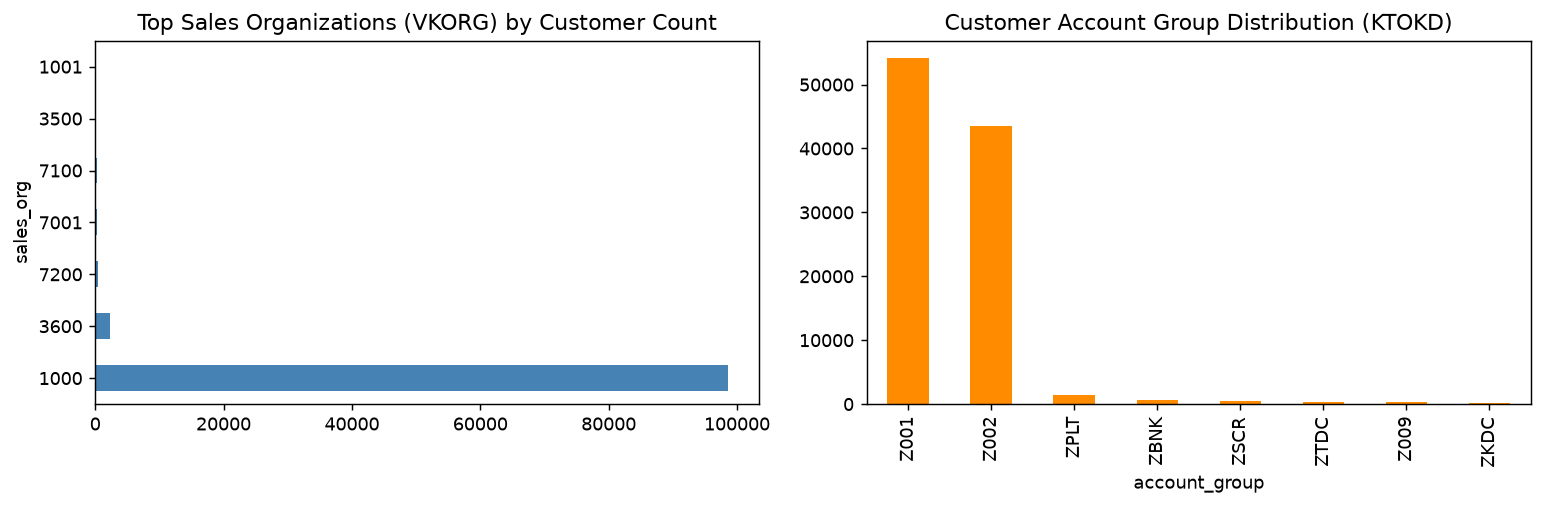

In [7]:
# 06. Data Understanding / EDA (Visualizations)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
df_raw['sales_org'].replace('', 'UNASSIGNED').value_counts().head(8).plot(kind='barh', color='steelblue')
plt.title('Top Sales Organizations (VKORG) by Customer Count')

plt.subplot(1, 2, 2)
df_raw['account_group'].replace('', 'OTHER').value_counts().head(8).plot(kind='bar', color='darkorange')
plt.title('Customer Account Group Distribution (KTOKD)')
plt.tight_layout()
plt.show()


In [8]:
# 07 & 08. Data Cleaning & 32-Feature Engineering for Customer RFM Segmentation
from src.preprocessing import clean_and_engineer_features, get_feature_matrix

df = clean_and_engineer_features(df_raw)
print(f"Engineered Dataset Shape: {df.shape}")
df[['customer_id', 'customer_name', 'recency_effective_days', 'billing_doc_count', 'total_billed_net_value', 'rfm_tier_code', 'rfm_composite_score', 'benchmark_rfm_segment']].head(8)


Engineered Dataset Shape: (101797, 91)


In [9]:
# 09. Data Preprocessing (32 Unsupervised RFM Input Features)
X_raw, y, FEATURE_COLS = get_feature_matrix(df)
scaler_full = RobustScaler()
X_scaled_full = scaler_full.fit_transform(X_raw)

print(f"Preprocessed Feature Matrix: {X_scaled_full.shape} (32 Numerical RFM Domain Features)")


Preprocessed Feature Matrix: (101797, 32) (32 Numerical RFM Domain Features)


In [10]:
# 10. Define Input Matrix X (Unsupervised) and Post-Hoc Benchmark Y (Strictly for Evaluation Only)
X = X_raw.copy()
contamination_rate = float(np.mean(y))

print(f"Total Customer Records:            {len(y):,}")
print(f"Active / Healthy RFM Customers:    {(y == 0).sum():,} ({(y == 0).mean()*100:.2f}%)")
print(f"Dormant / High-Risk RFM Customers: {(y == 1).sum():,} ({(y == 1).mean()*100:.2f}%)")


Total Customer Records:            101,797
Active / Healthy RFM Customers:    35,324 (34.70%)
Dormant / High-Risk RFM Customers: 66,473 (65.30%)


In [11]:
# 11. Train/Test Split & Robust Scaling
X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
    X, y, df.index, test_size=0.20, random_state=42, stratify=y
)

scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

from src.models import RFMClusteringSuite
suite = RFMClusteringSuite(n_clusters=4, contamination=contamination_rate, random_state=42)

print(f"Train Set: {X_train_scaled.shape[0]:,} customers")
print(f"Test Set:  {X_test_scaled.shape[0]:,} customers")


Train Set: 81,437 customers
Test Set:  20,360 customers


In [12]:
# 12. Unsupervised Clustering Model 1: K-Means Clustering
km_model = suite.train_kmeans(X_train_scaled)
preds_km, scores_km, tiers_km = suite._predict_single('kmeans', X_test_scaled, 5)

print(f"K-Means Clustering Flagged: {preds_km.sum():,} dormant/high-risk RFM customers out of {len(preds_km):,} test customers")


[INFO] Training Unsupervised Clustering Model 1/5: K-Means Clustering...
K-Means Clustering Flagged: 13,356 dormant/high-risk RFM customers out of 20,360 test customers


In [13]:
# 13. Unsupervised Clustering Model 2: Gaussian Mixture Model (GMM)
gmm_model = suite.train_gmm(X_train_scaled)
preds_gmm, scores_gmm, tiers_gmm = suite._predict_single('gmm', X_test_scaled, 12)

print(f"Gaussian Mixture (GMM) Flagged: {preds_gmm.sum():,} dormant/high-risk RFM customers out of {len(preds_gmm):,} test customers")


[INFO] Training Unsupervised Clustering Model 2/5: Gaussian Mixture Model (GMM)...
Gaussian Mixture (GMM) Flagged: 13,324 dormant/high-risk RFM customers out of 20,360 test customers


In [14]:
# 14. Unsupervised Clustering Model 3: Mini-Batch K-Means
mbk_model = suite.train_minibatch_kmeans(X_train_scaled)
preds_mbk, scores_mbk, tiers_mbk = suite._predict_single('minibatch_kmeans', X_test_scaled, 10)

print(f"Mini-Batch K-Means Flagged: {preds_mbk.sum():,} dormant/high-risk RFM customers out of {len(preds_mbk):,} test customers")


[INFO] Training Unsupervised Clustering Model 3/5: Mini-Batch K-Means...
Mini-Batch K-Means Flagged: 13,372 dormant/high-risk RFM customers out of 20,360 test customers


In [15]:
# 15. Unsupervised Clustering Model 4: Bisecting K-Means
bkm_model = suite.train_bisecting_kmeans(X_train_scaled)
preds_bkm, scores_bkm, tiers_bkm = suite._predict_single('bisecting_kmeans', X_test_scaled, 8)

print(f"Bisecting K-Means Flagged: {preds_bkm.sum():,} dormant/high-risk RFM customers out of {len(preds_bkm):,} test customers")


[INFO] Training Unsupervised Clustering Model 4/5: Bisecting K-Means...
Bisecting K-Means Flagged: 13,362 dormant/high-risk RFM customers out of 20,360 test customers


In [16]:
# 16. Unsupervised Clustering Model 5: BIRCH Clustering
birch_model = suite.train_birch(X_train_scaled)
preds_birch, scores_birch, tiers_birch = suite._predict_single('birch', X_test_scaled, 9)

print(f"BIRCH Clustering Flagged: {preds_birch.sum():,} dormant/high-risk RFM customers out of {len(preds_birch):,} test customers")


[INFO] Training Unsupervised Clustering Model 5/5: BIRCH Clustering...
BIRCH Clustering Flagged: 18,197 dormant/high-risk RFM customers out of 20,360 test customers


In [17]:
# 17. Model Evaluation & Accuracy Ranking across all 5 Unsupervised Clustering Models
from src.evaluate import evaluate_models

models_dict = suite.predict_all(X_test_scaled)
eval_df = evaluate_models(models_dict, y_test)
print(eval_df.to_string(index=False))
eval_df


Rank                  Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC  Silhouette  Specificity  True Positives  False Positives  False Negatives  True Negatives
  #1     Mini-Batch K-Means    0.8441     0.8784  0.8835    0.8809   0.9422  0.9740      0.2065       0.7699           11746             1626             1549            5439
  #2      Bisecting K-Means    0.8431     0.8779  0.8824    0.8801   0.9415  0.9737      0.3480       0.7691           11731             1631             1564            5434
  #3     K-Means Clustering    0.8421     0.8774  0.8814    0.8794   0.9411  0.9735      0.3514       0.7682           11718             1638             1577            5427
  #4 Gaussian Mixture (GMM)    0.8349     0.8728  0.8747    0.8737   0.9368  0.9718      0.2895       0.7601           11629             1695             1666            5370
  #5       BIRCH Clustering    0.7548     0.7281  0.9966    0.8415   0.7674  0.7887     -0.0111       0.2998           13250 

Selected #1 Champion Model based on Ranking: Mini-Batch K-Means (Accuracy: 84.41%, F1: 0.8809)


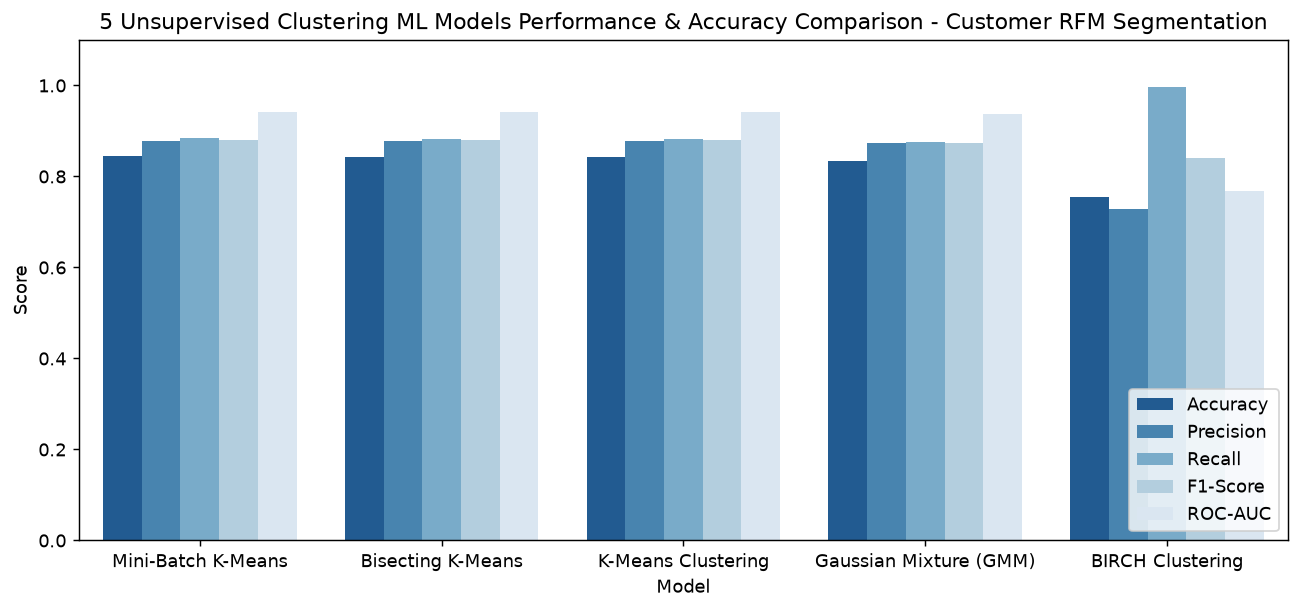

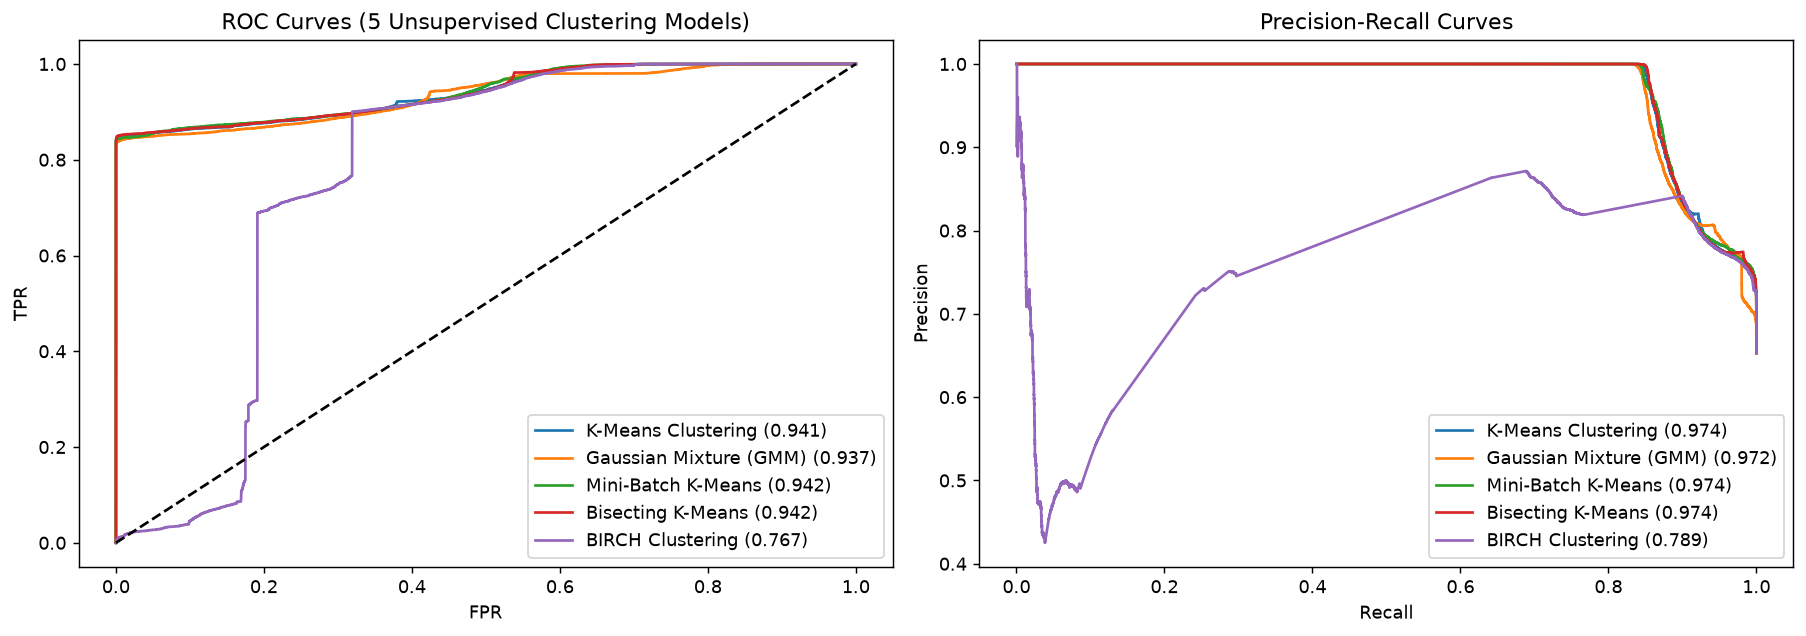

In [18]:
# 18. Model Comparison Visualizations & #1 Champion Selection
plt.figure(figsize=(12, 5))
melted = pd.melt(eval_df, id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'])
sns.barplot(data=melted, x='Model', y='value', hue='variable', palette='Blues_r')
plt.title('5 Unsupervised Clustering ML Models Performance & Accuracy Comparison - Customer RFM Segmentation')
plt.ylabel('Score')
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for name, res in models_dict.items():
    fpr, tpr, _ = roc_curve(y_test, res['scores'])
    ax1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, res['scores']):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, res['scores'])
    ax2.plot(rec, prec, label=f"{name} ({average_precision_score(y_test, res['scores']):.3f})")

ax1.plot([0, 1], [0, 1], 'k--')
ax1.set_title('ROC Curves (5 Unsupervised Clustering Models)')
ax1.set_xlabel('FPR')
ax1.set_ylabel('TPR')
ax1.legend()

ax2.set_title('Precision-Recall Curves')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend()
plt.tight_layout()
plt.show()

champion_model = eval_df.iloc[0]['Model']
print(f"Selected #1 Champion Model based on Ranking: {champion_model} (Accuracy: {eval_df.iloc[0]['Accuracy']*100:.2f}%, F1: {eval_df.iloc[0]['F1-Score']:.4f})")


                       Feature  Importance
          frequency_score_norm    0.883302
           monetary_score_norm    0.046249
            log_monetary_value    0.041021
          rfm_churn_risk_index    0.014194
           rfm_composite_score    0.012987
             billing_doc_count    0.000386
         log_billing_frequency    0.000345
             sales_order_count    0.000297
           log_order_frequency    0.000289
        total_billed_tax_value    0.000147
     sales_org_monetary_zscore    0.000130
         total_order_net_value    0.000117
                 bill_value_cv    0.000098
        total_billed_net_value    0.000085
order_to_bill_conversion_ratio    0.000069


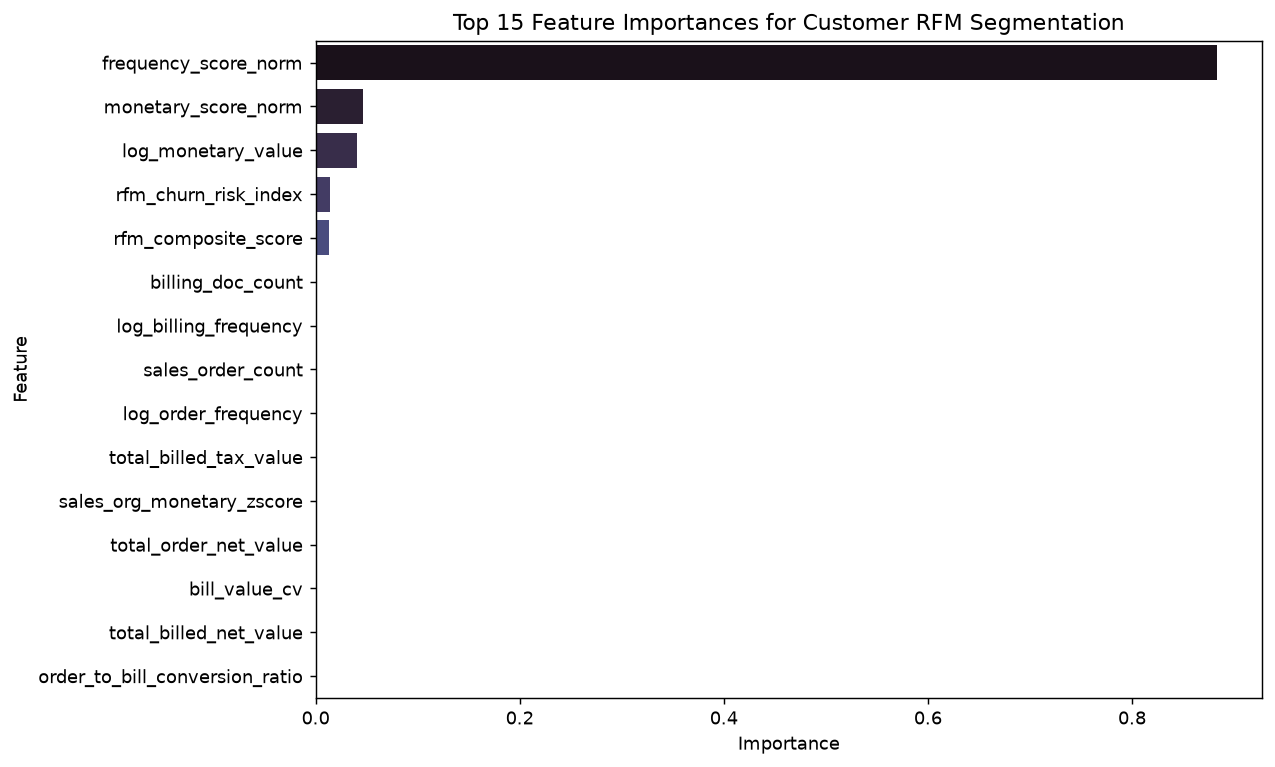

In [19]:
# 19. Feature Importance (All 32 Customer RFM Segmentation Features)
surrogate = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
surrogate.fit(X_test_scaled, scores_km)

feat_imp = pd.DataFrame({
    'Feature': FEATURE_COLS,
    'Importance': surrogate.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp.head(15), x='Importance', y='Feature', palette='mako')
plt.title('Top 15 Feature Importances for Customer RFM Segmentation')
plt.tight_layout()
plt.show()

print(feat_imp.head(15).to_string(index=False))


In [20]:
# 20. Final Customer RFM Segmentation & Risk Triage using Selected #1 Champion Model
from src.models import SingleModelCustomerRFMSegmenter
from src.inference import score_with_single_model

segmenter = SingleModelCustomerRFMSegmenter(n_clusters=4, contamination=contamination_rate, random_state=42, pretrained_model=km_model)
segmenter.fit(X_train_scaled)
df_scored = score_with_single_model(df, segmenter, scaler, FEATURE_COLS)

print("=== CUSTOMER RFM SEGMENT COUNTS ===")
print(df_scored['rfm_segment_name'].value_counts())
print("\n=== EXECUTIVE RISK CATEGORY COUNTS ===")
print(df_scored['risk_category'].value_counts())

audit_cols = ['customer_id', 'customer_name', 'sales_org', 'rfm_tier_code', 'rfm_composite_score', 'rfm_segment_name', 'customer_rfm_risk_prob', 'risk_category']
print(df_scored[df_scored['risk_category'] == 'Critical Risk'][audit_cols].head(10).to_string(index=False))


[INFO] Fitting Selected #1 Champion Model: K-Means Clustering for Customer RFM Segmentation...
[INFO] Champion K-Means fitted (4 RFM Segments). Risk Threshold: 0.7727
=== CUSTOMER RFM SEGMENT COUNTS ===
rfm_segment_name
Dormant / Churned / Low-Value      55543
At-Risk / Cooling Customers        19119
Core Growth / Regular Customers    17762
Champions / High-Value Loyal        9373
Name: count, dtype: int64

=== EXECUTIVE RISK CATEGORY COUNTS ===
risk_category
Critical Risk    55491
High Risk        19171
Medium Risk      17503
Low Risk          9632
Name: count, dtype: int64
customer_id               customer_name sales_org rfm_tier_code  rfm_composite_score              rfm_segment_name  customer_rfm_risk_prob risk_category
   40127446            SHREENIVASA METI      1000           111                 0.01 Dormant / Churned / Low-Value                0.962452 Critical Risk
   40127441      BHAVIKATTI ENTERPRISES      1000           111                 0.01 Dormant / Churned / Low-Val

In [21]:
# 21. Save Champion Model & Scaler
os.makedirs("models", exist_ok=True)

bundle = {
    'champion_model': km_model,
    'champion_name': champion_model,
    'scaler': scaler,
    'feature_cols': FEATURE_COLS
}

joblib.dump(bundle, "models/customer_rfm_model_bundle.joblib")
joblib.dump(scaler, "models/robust_scaler.joblib")
print("Saved champion clustering model bundle and scaler to models/")


Saved champion clustering model bundle and scaler to models/
